# NYC Flights 2013: exploratory analysis

All flights are retained for coverage. Delay rate = departures >=15 minutes late / observed departure-delay labels. Severity uses observed delays, including negative values. Missing labels are reported separately. All-year exploration is descriptive; future model tuning must not use test-period outcomes. No weather or causal claims.

Run all cells in order. Outputs are regenerated under outputs/; prepared CSVs are only read.

In [14]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/processed/flights_clean.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/flights_clean.csv').exists(), 'Run main.py first; open notebook from the project.'
FIGURES = ROOT / 'outputs/figures'
TABLES = ROOT / 'outputs/tables'
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)

def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

Python: 3.13.1 | pandas: 2.3.1


In [15]:
# Load and verify the prepared data; no imputation or sampling.
df = pd.read_csv(ROOT / 'data/processed/flights_clean.csv', parse_dates=['date'])
assert len(df) == 336776 and df.flight_id.is_unique
assert df.date.dt.year.eq(2013).all()
observed = df.dep_delay.notna()
assert df.loc[~observed, 'delayed_15'].isna().all()
assert df.loc[observed, 'delayed_15'].eq(df.loc[observed, 'dep_delay'].ge(15).astype(int)).all()
print(f'Flights: {len(df):,}; observed labels: {observed.sum():,}; missing: {(~observed).sum():,}')
display(df[['date', 'origin', 'dest', 'dep_delay', 'delayed_15']].head())
display(df.dtypes.rename('dtype').to_frame())
display(df.isna().sum().rename('missing').to_frame().query('missing > 0'))

def summarize(keys):
    result = df.groupby(keys, observed=True).agg(
        flights=('flight_id', 'size'), observed_labels=('dep_delay', 'count'),
        delayed=('delayed_15', 'sum'), mean_delay=('dep_delay', 'mean'),
        median_delay=('dep_delay', 'median'), p90_delay=('dep_delay', lambda x: x.quantile(.9)))
    result['missing_labels'] = result.flights - result.observed_labels
    result['delay_rate'] = result.delayed / result.observed_labels.replace(0, np.nan)
    result['missing_rate'] = result.missing_labels / result.flights
    assert result.flights.sum() == len(df)
    return result

monthly = summarize('month')
weekly = summarize(pd.Grouper(key='date', freq='W-SUN'))
airlines = summarize('carrier')
airports = summarize('origin')
routes = summarize('route')
hourly = summarize('hour')
daily = summarize('date')
for name, table in [('monthly', monthly), ('weekly', weekly), ('airlines', airlines),
                    ('airports', airports), ('routes', routes), ('hourly', hourly), ('daily', daily)]:
    table.to_csv(TABLES / f'{name}.csv')
display(monthly.round(3))

Flights: 336,776; observed labels: 328,521; missing: 8,255


,date,origin,dest,dep_delay,delayed_15
0,2013-01-01,EWR,IAH,2.0,0.0
1,2013-01-01,LGA,IAH,4.0,0.0
2,2013-01-01,JFK,MIA,2.0,0.0
3,2013-01-01,JFK,BQN,-1.0,0.0
4,2013-01-01,LGA,ATL,-6.0,0.0


,dtype
flight_id,int64
year,int64
month,int64
day,int64
dep_time,float64
sched_dep_time,int64
dep_delay,float64
arr_time,float64
sched_arr_time,int64
arr_delay,float64


,missing
dep_time,8255
dep_delay,8255
arr_time,8713
arr_delay,9430
tailnum,2512
air_time,9430
delayed_15,8255


,flights,observed_labels,delayed,mean_delay,median_delay,p90_delay,missing_labels,delay_rate,missing_rate
month,,,,,,,,,
1,27004,26483,5091.0,10.037,-2.0,40.0,521,0.192,0.019
2,24951,23690,4961.0,10.817,-2.0,43.0,1261,0.209,0.051
3,28834,27973,6416.0,13.227,-1.0,52.0,861,0.229,0.030
4,28330,27662,6405.0,13.938,-2.0,56.0,668,0.232,0.024
5,28796,28233,6645.0,12.987,-1.0,51.0,563,0.235,0.020
6,28243,27234,8016.0,20.846,0.0,77.0,1009,0.294,0.036
7,29425,28485,8639.0,21.728,0.0,79.0,940,0.303,0.032
8,29327,28841,6592.0,12.611,-1.0,49.0,486,0.229,0.017
9,27574,27122,3908.0,6.722,-3.0,26.0,452,0.144,0.016


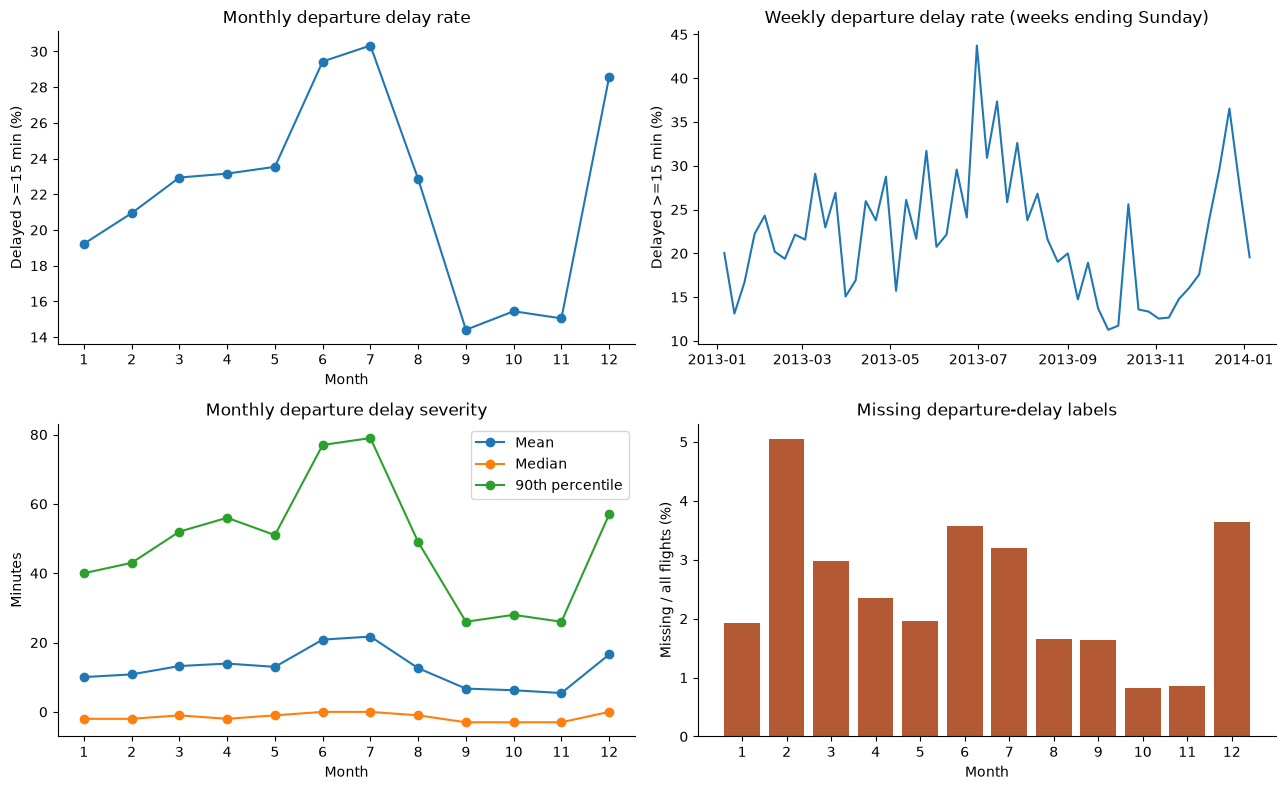

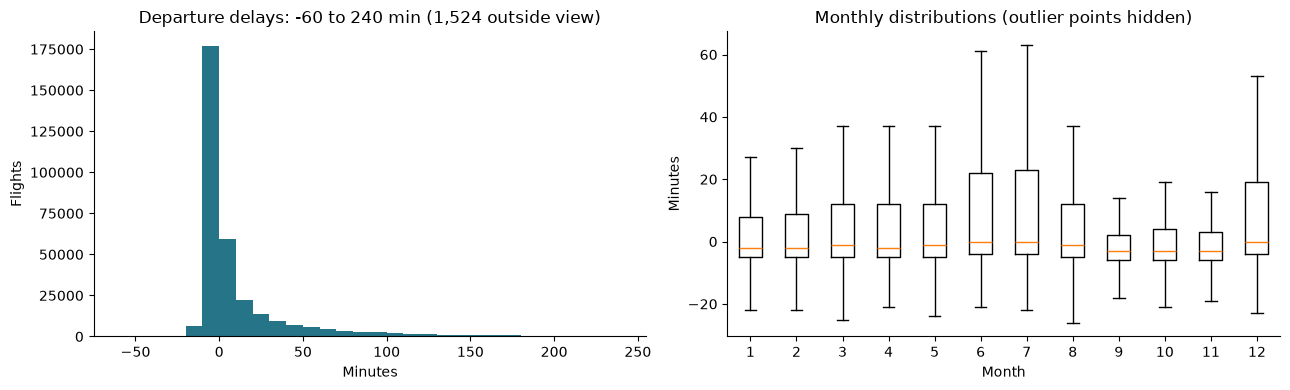

Full observed departure-delay range: -43.0 to 1301.0 minutes


In [16]:
# Temporal comparisons. First and last weekly buckets are partial weeks.
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(monthly.index, monthly.delay_rate * 100, marker='o')
axes[0, 0].set(title='Monthly departure delay rate', xlabel='Month', ylabel='Delayed >=15 min (%)', xticks=range(1, 13))
axes[0, 1].plot(weekly.index, weekly.delay_rate * 100)
axes[0, 1].set(title='Weekly departure delay rate (weeks ending Sunday)', ylabel='Delayed >=15 min (%)')
for col, label in [('mean_delay', 'Mean'), ('median_delay', 'Median'), ('p90_delay', '90th percentile')]:
    axes[1, 0].plot(monthly.index, monthly[col], marker='o', label=label)
axes[1, 0].set(title='Monthly departure delay severity', xlabel='Month', ylabel='Minutes', xticks=range(1, 13))
axes[1, 0].legend()
axes[1, 1].bar(monthly.index, monthly.missing_rate * 100, color='#b35a35')
axes[1, 1].set(title='Missing departure-delay labels', xlabel='Month', ylabel='Missing / all flights (%)', xticks=range(1, 13))
save('temporal_trends')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
values = df.dep_delay.dropna()
axes[0].hist(values, bins=np.arange(-60, 241, 10), color='#267487')
outside = ((values < -60) | (values > 240)).sum()
axes[0].set(title=f'Departure delays: -60 to 240 min ({outside:,} outside view)', xlabel='Minutes', ylabel='Flights')
axes[1].boxplot([df.loc[df.month.eq(m), 'dep_delay'].dropna() for m in range(1, 13)], showfliers=False)
axes[1].set(title='Monthly distributions (outlier points hidden)', xlabel='Month', ylabel='Minutes')
save('delay_distributions')
print('Full observed departure-delay range:', values.min(), 'to', values.max(), 'minutes')

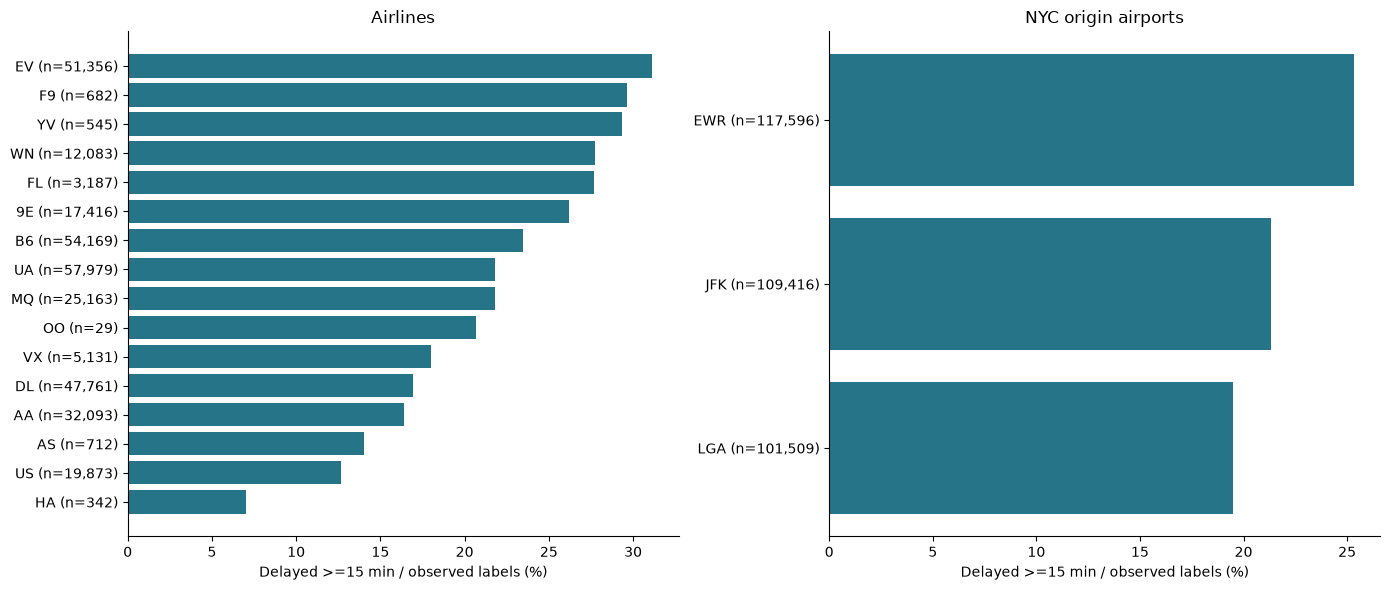

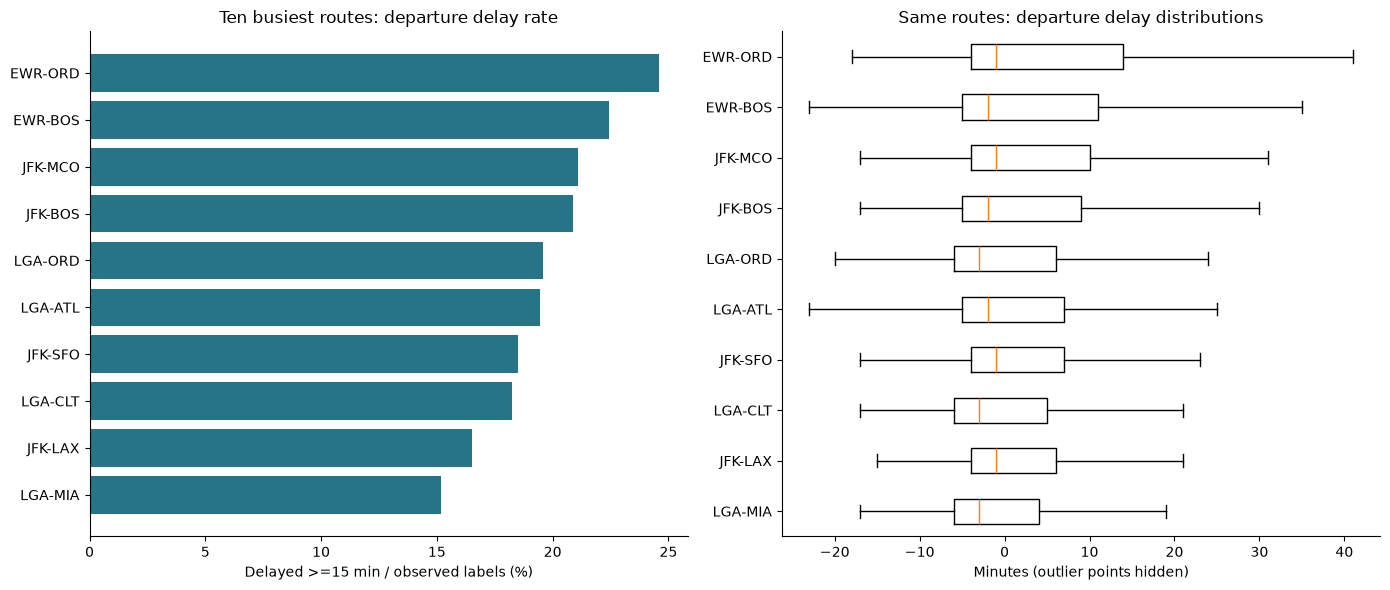

,flights,observed_labels,delay_rate,missing_rate
carrier,,,,
9E,18460,17416,0.262,0.057
AA,32729,32093,0.164,0.019
AS,714,712,0.140,0.003
B6,54635,54169,0.235,0.009
DL,48110,47761,0.169,0.007
EV,54173,51356,0.311,0.052
F9,685,682,0.296,0.004
FL,3260,3187,0.277,0.022
HA,342,342,0.070,0.000


,flights,observed_labels,delay_rate,median_delay,p90_delay
route,,,,,
LGA-MIA,5781,5725,0.152,-3.0,29.0
JFK-LAX,11262,11196,0.165,-1.0,30.0
LGA-CLT,6168,5969,0.183,-3.0,40.0
JFK-SFO,8204,8138,0.185,-1.0,42.0
LGA-ATL,10263,10082,0.195,-2.0,42.0
LGA-ORD,8857,8548,0.196,-3.0,46.0
JFK-BOS,5898,5786,0.209,-2.0,48.0
JFK-MCO,5464,5434,0.211,-1.0,38.0
EWR-BOS,5327,5251,0.225,-2.0,51.0


In [17]:
# Descriptive comparisons: differences may reflect routes, schedules and flight mix.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, table, title in [(axes[0], airlines, 'Airlines'), (axes[1], airports, 'NYC origin airports')]:
    ranked = table.sort_values('delay_rate')
    labels = [f'{name} (n={int(n):,})' for name, n in ranked.observed_labels.items()]
    ax.barh(labels, ranked.delay_rate * 100, color='#267487')
    ax.set(title=title, xlabel='Delayed >=15 min / observed labels (%)')
save('airline_airport_comparison')

selected = routes.nlargest(10, 'flights').sort_values('delay_rate')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(selected.index, selected.delay_rate * 100, color='#267487')
axes[0].set(title='Ten busiest routes: departure delay rate', xlabel='Delayed >=15 min / observed labels (%)')
axes[1].boxplot([df.loc[df.route.eq(r), 'dep_delay'].dropna() for r in selected.index], orientation='horizontal', showfliers=False, tick_labels=selected.index)
axes[1].set(title='Same routes: departure delay distributions', xlabel='Minutes (outlier points hidden)')
save('selected_routes')
selected.to_csv(TABLES / 'selected_routes.csv')
display(airlines[['flights', 'observed_labels', 'delay_rate', 'missing_rate']].round(3))
display(selected[['flights', 'observed_labels', 'delay_rate', 'median_delay', 'p90_delay']].round(3))

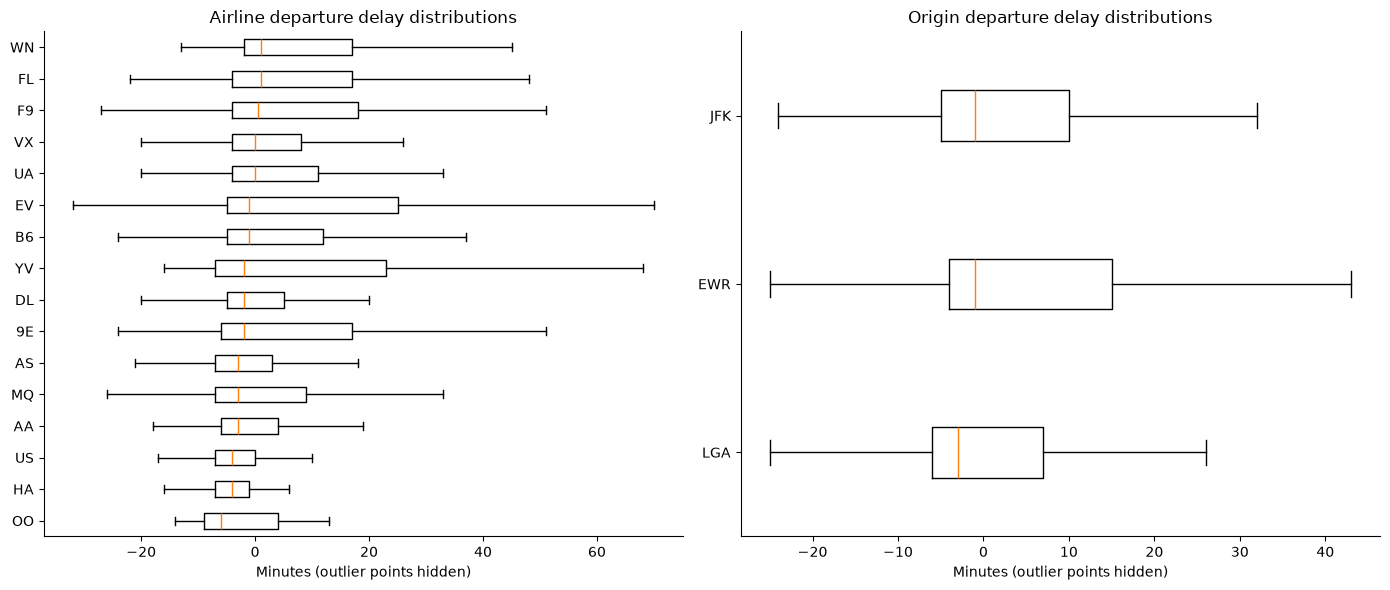

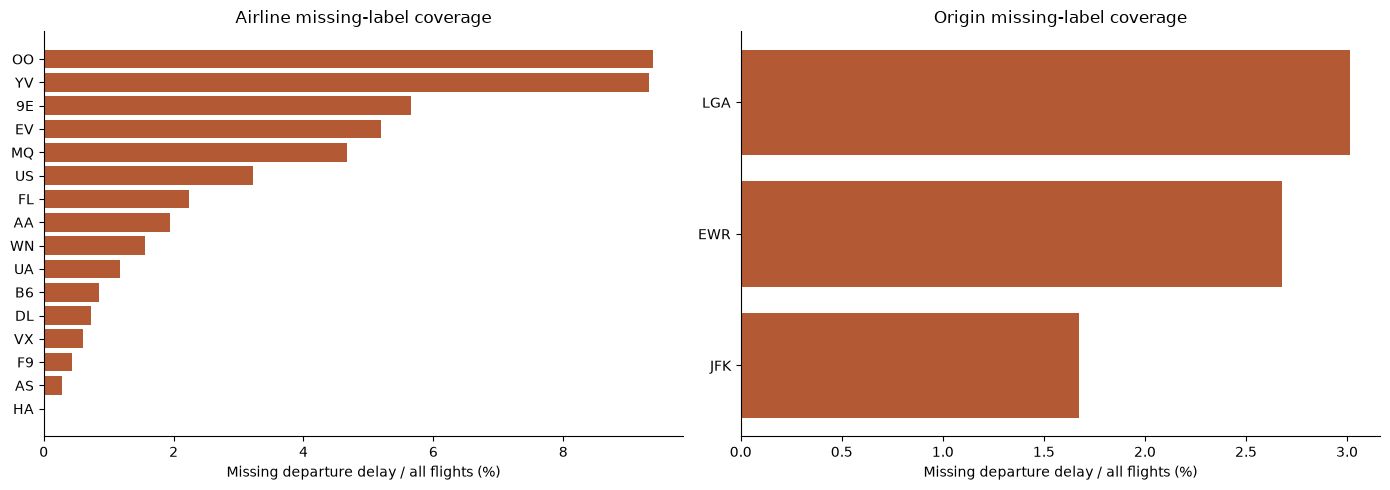

,flights,observed_labels,missing_labels,missing_rate
origin,,,,
EWR,120835,117596,3239,0.027
JFK,111279,109416,1863,0.017
LGA,104662,101509,3153,0.030


In [18]:
# Compare distributions and missing-label coverage across carriers and origins.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, key, table, title in [(axes[0], 'carrier', airlines, 'Airline departure delay distributions'), (axes[1], 'origin', airports, 'Origin departure delay distributions')]:
    order = table.sort_values('median_delay').index
    ax.boxplot([df.loc[df[key].eq(name), 'dep_delay'].dropna() for name in order], orientation='horizontal', showfliers=False, tick_labels=order)
    ax.set(title=title, xlabel='Minutes (outlier points hidden)')
save('airline_airport_distributions')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [(axes[0], airlines, 'Airline missing-label coverage'), (axes[1], airports, 'Origin missing-label coverage')]:
    ranked = table.sort_values('missing_rate')
    ax.barh(ranked.index, ranked.missing_rate * 100, color='#b35a35')
    ax.set(title=title, xlabel='Missing departure delay / all flights (%)')
save('airline_airport_missing_labels')
display(airports[['flights', 'observed_labels', 'missing_labels', 'missing_rate']].round(3))

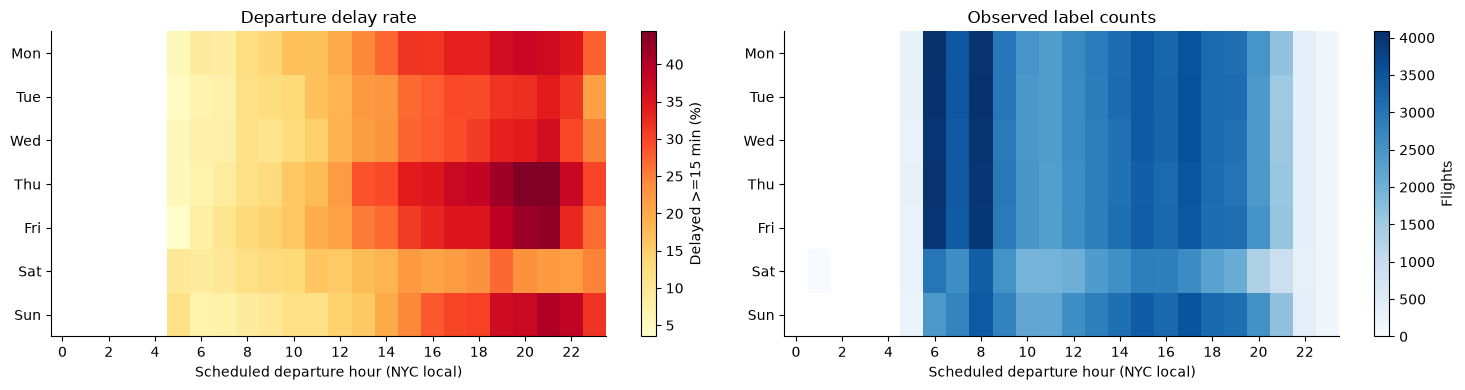

Heatmap counts reconcile: True


In [19]:
# Weekday x scheduled departure hour; retain counts to expose sparse cells.
heat = df.groupby(['day_of_week', 'hour']).agg(flights=('flight_id', 'size'), observed_labels=('dep_delay', 'count'), delayed=('delayed_15', 'sum'))
heat['delay_rate'] = heat.delayed / heat.observed_labels.replace(0, np.nan)
heat.to_csv(TABLES / 'weekday_hour.csv')
rate = heat.delay_rate.unstack().reindex(index=range(7), columns=range(24))
counts = heat.observed_labels.unstack().reindex(index=range(7), columns=range(24))
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, grid, title, label, cmap in [(axes[0], rate * 100, 'Departure delay rate', 'Delayed >=15 min (%)', 'YlOrRd'), (axes[1], counts, 'Observed label counts', 'Flights', 'Blues')]:
    image = ax.imshow(grid, aspect='auto', cmap=cmap)
    ax.set(title=title, xlabel='Scheduled departure hour (NYC local)', xticks=range(0, 24, 2), yticks=range(7), yticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
    fig.colorbar(image, ax=ax, label=label)
save('weekday_hour_heatmap')
print('Heatmap counts reconcile:', int(heat.observed_labels.sum()) == int(observed.sum()))

In [20]:
# Generate findings directly from computed summaries.
worst, best = monthly.delay_rate.idxmax(), monthly.delay_rate.idxmin()
summary = [
    '# Exploratory findings: NYC Flights 2013', '',
    f'Coverage: {len(df):,} flights; {observed.sum():,} observed departure delays; {(~observed).sum():,} missing ({(~observed).mean():.2%}).',
    f'Overall departure delay rate (>=15 minutes): {df.delayed_15.mean():.2%} among observed labels.',
    f'Highest monthly rate: month {worst}, {monthly.loc[worst, "delay_rate"]:.2%}; lowest: month {best}, {monthly.loc[best, "delay_rate"]:.2%}.',
    f'Median delay: {values.median():.1f} min; mean: {values.mean():.1f}; 90th percentile: {values.quantile(.9):.1f}.',
    'Origin rates: ' + '; '.join(f'{name}: {row.delay_rate:.2%} (observed n={int(row.observed_labels):,})' for name, row in airports.iterrows()) + '.',
    f'Highest airline rate: {airlines.delay_rate.idxmax()} ({airlines.delay_rate.max():.2%}); lowest: {airlines.delay_rate.idxmin()} ({airlines.delay_rate.min():.2%}). See airlines.csv for flight counts.',
    f'Highest scheduled-hour rate: {hourly.delay_rate.idxmax()}:00 ({hourly.delay_rate.max():.2%}, observed n={int(hourly.loc[hourly.delay_rate.idxmax(), "observed_labels"]):,}). Sparse hours can be unstable; inspect the count heatmap.', '',
    '## Interpretation and limitations', '',
    'Route comparisons use the ten busiest routes by total flights, not extreme delay rates.',
    'Missing labels are unknown, not on-time flights. Rates exclude missing labels; counts remain visible.',
    'Charts that hide outliers or limit the display range retain all observed values in summary statistics.',
    'Weekly buckets end Sunday; first and last buckets cover partial weeks.',
    'Airline, route and hour differences are unadjusted descriptive associations, not causal effects.',
    'All-year EDA includes held-out months for historical description only. Future model selection must use training/validation data; final test metrics remain reserved for final evaluation.',
    'One year of NYC departures cannot establish recurring annual trends. Weather is excluded.',
    'Daily summaries are exported for later clustering and anomaly detection. Neither is performed here.',
]
text = chr(10).join(summary) + chr(10)
(ROOT / 'reports/eda_findings.md').write_text(text, encoding='utf-8')
print(text)

# Exploratory findings: NYC Flights 2013

Coverage: 336,776 flights; 328,521 observed departure delays; 8,255 missing (2.45%).
Overall departure delay rate (>=15 minutes): 22.19% among observed labels.
Highest monthly rate: month 7, 30.33%; lowest: month 9, 14.41%.
Median delay: -2.0 min; mean: 12.6; 90th percentile: 49.0.
Origin rates: EWR: 25.32% (observed n=117,596); JFK: 21.34% (observed n=109,416); LGA: 19.50% (observed n=101,509).
Highest airline rate: EV (31.14%); lowest: HA (7.02%). See airlines.csv for flight counts.
Highest scheduled-hour rate: 21:00 (37.85%, observed n=10,524). Sparse hours can be unstable; inspect the count heatmap.

## Interpretation and limitations

Route comparisons use the ten busiest routes by total flights, not extreme delay rates.
Missing labels are unknown, not on-time flights. Rates exclude missing labels; counts remain visible.
Charts that hide outliers or limit the display range retain all observed values in summary statistics.
Weekly buckets end

## Follow-up 1: was July broadly difficult, or driven by a few days?
Compare daily distributions across months, then remove the five highest-rate July days as a descriptive sensitivity check. This is not a cleaned estimate: those days are real observations. Break July down by airport and major carrier to see how widespread the pattern is.

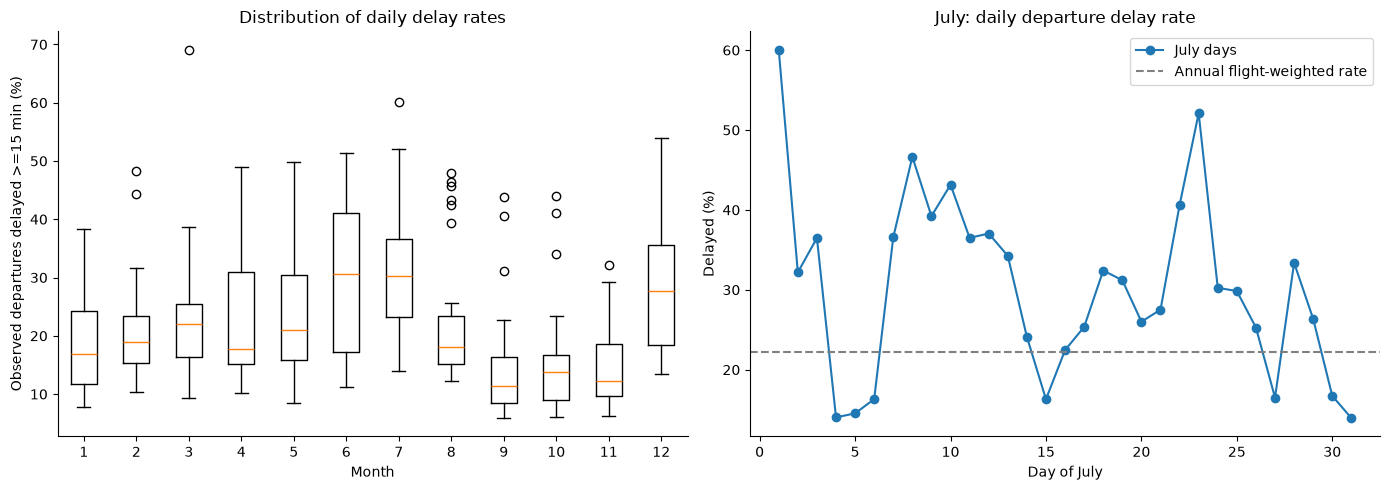

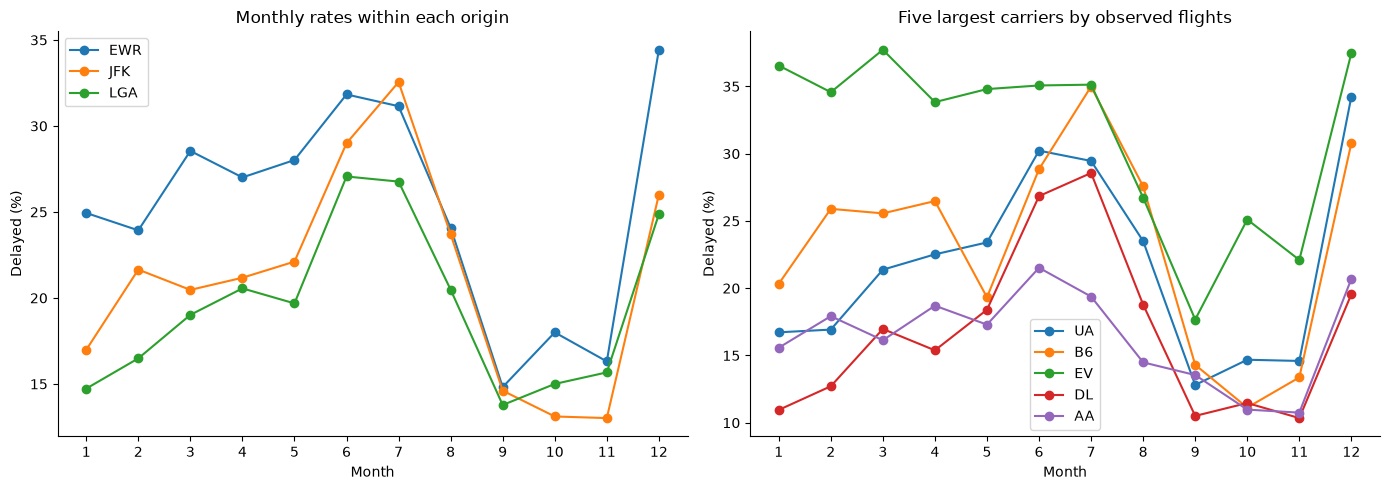

July rate: 30.33%. Its five highest-rate days account for 25.2% of July delayed flights. Excluding those five days, the remaining rate is 26.92%, versus 22.19% annually. July daily median: 30.25%. The exclusion is a sensitivity check, not a replacement for the full-month result. July rates exceed each origin annual rate at 3/3 origins. Together with the remaining-days result, this suggests the elevated monthly rate extends beyond a few extreme dates.

,flights,observed_labels,delay_rate,median_delay,p90_delay,missing_rate
date,,,,,,
2013-07-01,966,881,0.600,30.0,158.0,0.088
2013-07-23,997,902,0.521,19.0,130.0,0.095
2013-07-08,1004,954,0.466,11.5,121.0,0.050
2013-07-10,1004,883,0.431,7.0,191.4,0.121
2013-07-22,1000,877,0.406,5.0,169.4,0.123


In [21]:
from IPython.display import Markdown
july = daily.loc[daily.index.month == 7].copy()
top_july = july.nlargest(5, 'delay_rate')
remaining = july.drop(top_july.index)
remaining_rate = remaining.delayed.sum() / remaining.observed_labels.sum()
july_share = top_july.delayed.sum() / july.delayed.sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([daily.loc[daily.index.month == m, 'delay_rate'] * 100 for m in range(1, 13)], showfliers=True)
axes[0].set(title='Distribution of daily delay rates', xlabel='Month', ylabel='Observed departures delayed >=15 min (%)')
axes[1].plot(july.index.day, july.delay_rate * 100, marker='o', label='July days')
axes[1].axhline(df.delayed_15.mean() * 100, linestyle='--', color='gray', label='Annual flight-weighted rate')
axes[1].set(title='July: daily departure delay rate', xlabel='Day of July', ylabel='Delayed (%)')
axes[1].legend()
save('followup_july_daily')
airport_month = df.groupby(['origin', 'month']).agg(observed_labels=('dep_delay', 'count'), delayed=('delayed_15', 'sum'))
airport_month['delay_rate'] = airport_month.delayed / airport_month.observed_labels.replace(0, np.nan)
carrier_month = df.groupby(['carrier', 'month']).agg(observed_labels=('dep_delay', 'count'), delayed=('delayed_15', 'sum'))
carrier_month['delay_rate'] = carrier_month.delayed / carrier_month.observed_labels.replace(0, np.nan)
major_carriers = airlines.nlargest(5, 'observed_labels').index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for origin in airports.index:
    axes[0].plot(range(1, 13), airport_month.loc[origin].delay_rate * 100, marker='o', label=origin)
for carrier in major_carriers:
    axes[1].plot(range(1, 13), carrier_month.loc[carrier].delay_rate * 100, marker='o', label=carrier)
for ax, title in zip(axes, ['Monthly rates within each origin', 'Five largest carriers by observed flights']):
    ax.set(title=title, xlabel='Month', ylabel='Delayed (%)', xticks=range(1, 13))
    ax.legend()
save('followup_july_groups')
airport_month.to_csv(TABLES / 'airport_month.csv')
carrier_month.to_csv(TABLES / 'carrier_month.csv')
top_july.to_csv(TABLES / 'july_top_days.csv')
july_text = f'July rate: {monthly.loc[7, "delay_rate"]:.2%}. Its five highest-rate days account for {july_share:.1%} of July delayed flights. Excluding those five days, the remaining rate is {remaining_rate:.2%}, versus {df.delayed_15.mean():.2%} annually. July daily median: {july.delay_rate.median():.2%}. The exclusion is a sensitivity check, not a replacement for the full-month result.'
july_origins = airport_month.xs(7, level='month').delay_rate
july_above = int(july_origins.gt(airports.delay_rate).sum())
july_text += f' July rates exceed each origin annual rate at {july_above}/{len(july_origins)} origins. Together with the remaining-days result, this suggests the elevated monthly rate extends beyond a few extreme dates.'
display(Markdown(july_text))
display(top_july[['flights', 'observed_labels', 'delay_rate', 'median_delay', 'p90_delay', 'missing_rate']].round(3))

## Follow-up 2: what did the most disrupted days look like?
Rank days by delay rate among at least 500 observed departures. Separately inspect missing-label rates and the severity tail: a day can have serious disruption even when its observable delay rate is modest. Compare each selected day's origins and carriers against their own annual rates; these comparisons are descriptive, not formal anomaly detection.

,flights,observed_labels,delay_rate,median_delay,p90_delay,missing_rate
date,,,,,,
2013-03-08,979,799,0.691,58.0,222.2,0.184
2013-07-01,966,881,0.600,30.0,158.0,0.088
2013-12-17,949,839,0.539,18.0,117.2,0.116
2013-07-23,997,902,0.521,19.0,130.0,0.095
2013-06-13,989,894,0.513,16.0,139.0,0.096
2013-05-08,965,900,0.499,14.0,146.1,0.067
2013-06-25,993,952,0.494,13.0,136.9,0.041
2013-06-28,994,871,0.493,13.0,152.0,0.124
2013-04-12,989,916,0.489,13.0,108.0,0.074


,flights,observed_labels,delay_rate,missing_rate
date,,,,
2013-02-09,684,291,0.316,0.575
2013-02-08,930,458,0.273,0.508
2013-05-23,988,767,0.447,0.224
2013-12-10,943,739,0.418,0.216
2013-09-12,992,800,0.406,0.194


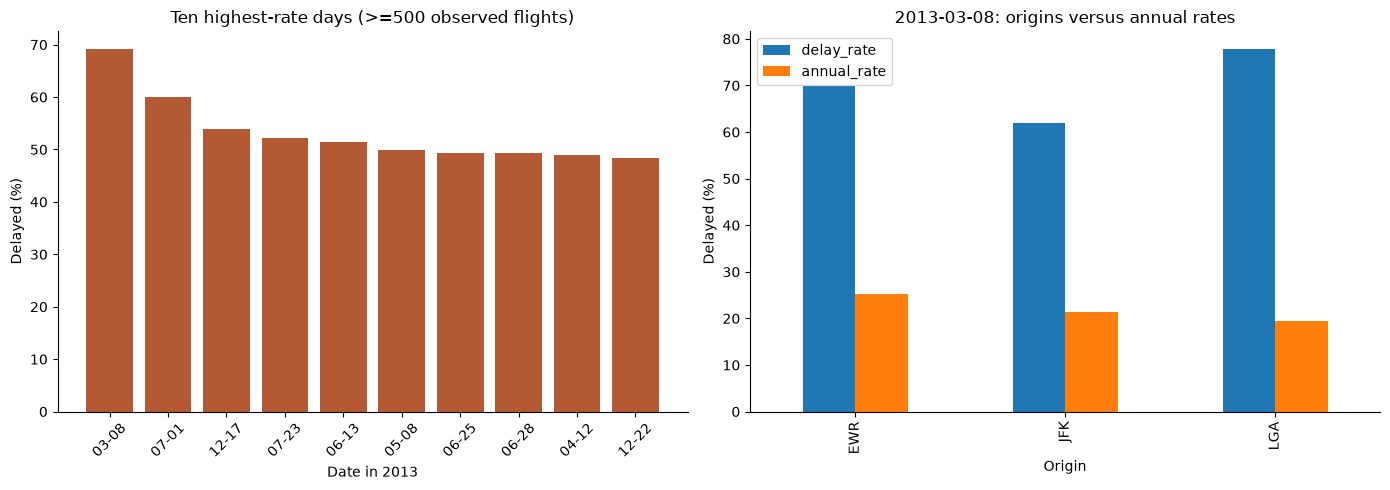

,flights,observed_labels,delayed,median_delay,p90_delay,delay_rate,annual_rate,missing_rate
origin,,,,,,,,
EWR,354,266,186.0,68.5,271.0,0.699,0.253,0.249
JFK,320,304,188.0,34.5,134.0,0.618,0.213,0.050
LGA,305,229,178.0,91.0,232.6,0.777,0.195,0.249


,observed_labels,delayed,delay_rate,annual_rate
carrier,,,,
9E,42,23.0,0.548,0.262
AA,91,62.0,0.681,0.164
B6,154,116.0,0.753,0.235
DL,131,88.0,0.672,0.169
EV,83,68.0,0.819,0.311
MQ,48,31.0,0.646,0.218
UA,162,111.0,0.685,0.218
US,39,19.0,0.487,0.126


The highest-rate eligible day is 2013-03-08: 69.09% delayed, with 799 observed labels and 18.39% missing. 3 of 3 origins exceed their annual rates that day. The highest missing-label share occurs on 2013-02-09 (57.46%); this is a separate signal, not a confirmed cancellation count. These tables locate disruption but cannot establish its cause.

In [22]:
MIN_DAILY_LABELS = 500
eligible_days = daily.loc[daily.observed_labels >= MIN_DAILY_LABELS]
worst_days = eligible_days.nlargest(10, 'delay_rate')
worst_days.to_csv(TABLES / 'worst_days.csv')
display(worst_days[['flights', 'observed_labels', 'delay_rate', 'median_delay', 'p90_delay', 'missing_rate']].round(3))
display(daily.nlargest(5, 'missing_rate')[['flights', 'observed_labels', 'delay_rate', 'missing_rate']].round(3))
focus_date = worst_days.index[0]
focus = df.loc[df.date.eq(focus_date)]
origin_focus = focus.groupby('origin').agg(flights=('flight_id', 'size'), observed_labels=('dep_delay', 'count'), delayed=('delayed_15', 'sum'), median_delay=('dep_delay', 'median'), p90_delay=('dep_delay', lambda x: x.quantile(.9)))
origin_focus['delay_rate'] = origin_focus.delayed / origin_focus.observed_labels.replace(0, np.nan)
origin_focus['annual_rate'] = airports.delay_rate
origin_focus['missing_rate'] = 1 - origin_focus.observed_labels / origin_focus.flights
carrier_focus = focus.groupby('carrier').agg(observed_labels=('dep_delay', 'count'), delayed=('delayed_15', 'sum'))
carrier_focus['delay_rate'] = carrier_focus.delayed / carrier_focus.observed_labels.replace(0, np.nan)
carrier_focus['annual_rate'] = airlines.delay_rate
carrier_focus = carrier_focus.loc[carrier_focus.observed_labels >= 30]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(worst_days.index.strftime('%m-%d'), worst_days.delay_rate * 100, color='#b35a35')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set(title='Ten highest-rate days (>=500 observed flights)', xlabel='Date in 2013', ylabel='Delayed (%)')
(origin_focus[['delay_rate', 'annual_rate']] * 100).plot.bar(ax=axes[1])
axes[1].set(title=f'{focus_date:%Y-%m-%d}: origins versus annual rates', xlabel='Origin', ylabel='Delayed (%)')
save('followup_disrupted_days')
origin_focus.to_csv(TABLES / 'worst_day_origins.csv')
carrier_focus.to_csv(TABLES / 'worst_day_carriers.csv')
display(origin_focus.round(3))
display(carrier_focus.round(3))
above_origins = int(origin_focus.delay_rate.gt(origin_focus.annual_rate).sum())
worst_missing = daily.missing_rate.idxmax()
disruption_text = f'The highest-rate eligible day is {focus_date:%Y-%m-%d}: {worst_days.iloc[0].delay_rate:.2%} delayed, with {int(worst_days.iloc[0].observed_labels):,} observed labels and {worst_days.iloc[0].missing_rate:.2%} missing. {above_origins} of {len(origin_focus)} origins exceed their annual rates that day. The highest missing-label share occurs on {worst_missing:%Y-%m-%d} ({daily.loc[worst_missing, "missing_rate"]:.2%}); this is a separate signal, not a confirmed cancellation count. These tables locate disruption but cannot establish its cause.'
display(Markdown(disruption_text))

## Follow-up 3: do airline differences persist on comparable schedules?
For the three busiest routes served by at least two carriers with >=500 observed flights each, compare the two largest eligible carriers. Use common month × four-hour scheduled-departure bands with >=20 observed flights per carrier. Apply identical pooled-flight weights to both carriers in those shared cells. Report overlap coverage: results concern only this subset, not overall airline quality. The thresholds are fixed descriptive choices, not tuned to obtain a ranking.

,route,carrier,route_observed,shared_observed,coverage,shared_cells,raw_route_rate,raw_shared_rate,standardized_rate
0,JFK-LAX,AA,3196,3189,0.998,57,0.166,0.166,0.178
1,JFK-LAX,DL,2492,2405,0.965,57,0.140,0.143,0.134
2,LGA-ATL,DL,5486,4794,0.874,46,0.156,0.143,0.146
3,LGA-ATL,FL,2289,2287,0.999,46,0.278,0.278,0.267
4,LGA-ORD,AA,5515,5370,0.974,53,0.179,0.177,0.176
5,LGA-ORD,UA,3032,2901,0.957,53,0.227,0.221,0.222


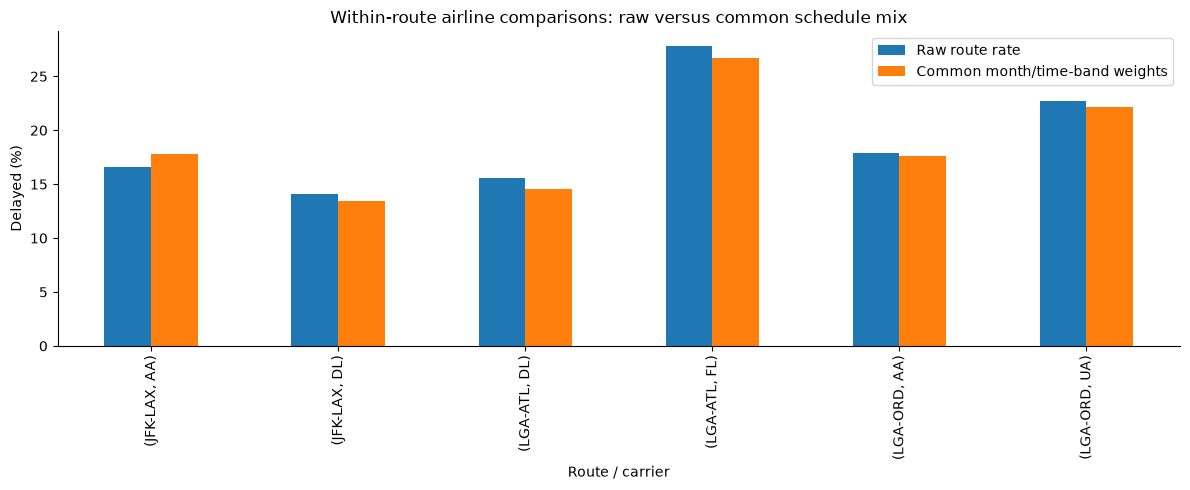

JFK-LAX: AA 17.80% versus DL 13.45%, a signed difference of 4.3 percentage points; overlap coverage 96.5% to 99.8%. LGA-ATL: DL 14.56% versus FL 26.67%, a signed difference of -12.1 percentage points; overlap coverage 87.4% to 99.9%. LGA-ORD: AA 17.65% versus UA 22.16%, a signed difference of -4.5 percentage points; overlap coverage 95.7% to 97.4%. These comparisons hold route fixed and align month/time-band weights on shared support. Coverage and raw-shared rates expose selection effects from excluding non-overlapping schedules. Remaining differences may reflect flight mix, day-specific conditions, or other unmeasured factors; they are not causal airline effects.

In [23]:
comparison = df.loc[observed].copy()
comparison['time_band'] = (comparison.hour // 4) * 4
route_carrier_counts = comparison.groupby(['route', 'carrier']).size()
eligible_pairs = route_carrier_counts.loc[route_carrier_counts >= 500]
shared_routes = eligible_pairs.groupby(level='route').size()
shared_routes = shared_routes.loc[shared_routes >= 2].index
chosen_routes = routes.loc[routes.index.isin(shared_routes)].nlargest(3, 'flights').index
matched_rows = []
for route in chosen_routes:
    carriers = eligible_pairs.loc[route].nlargest(2).index.tolist()
    subset = comparison.loc[comparison.route.eq(route) & comparison.carrier.isin(carriers)]
    cells = subset.groupby(['month', 'time_band', 'carrier']).delayed_15.agg(['size', 'mean'])
    counts = cells['size'].unstack('carrier').reindex(columns=carriers)
    rates = cells['mean'].unstack('carrier').reindex(columns=carriers)
    shared = counts.ge(20).all(axis=1)
    common_counts, common_rates = counts.loc[shared], rates.loc[shared]
    if common_counts.empty:
        continue
    weights = common_counts.sum(axis=1)
    weights = weights / weights.sum()
    assert np.isclose(weights.sum(), 1)
    for carrier in carriers:
        full = subset.loc[subset.carrier.eq(carrier)]
        matched_rows.append({'route': route, 'carrier': carrier, 'route_observed': len(full),
            'shared_observed': int(common_counts[carrier].sum()),
            'coverage': common_counts[carrier].sum() / len(full), 'shared_cells': len(weights),
            'raw_route_rate': full.delayed_15.mean(),
            'raw_shared_rate': (common_rates[carrier] * common_counts[carrier]).sum() / common_counts[carrier].sum(),
            'standardized_rate': (common_rates[carrier] * weights).sum()})
matched = pd.DataFrame(matched_rows)
assert not matched.empty, 'No supported comparisons under the declared thresholds.'
matched.to_csv(TABLES / 'matched_airline_comparisons.csv', index=False)
display(matched.round(3))
fig, ax = plt.subplots(figsize=(12, 5))
matched.set_index(['route', 'carrier'])[['raw_route_rate', 'standardized_rate']].mul(100).plot.bar(ax=ax)
ax.set(title='Within-route airline comparisons: raw versus common schedule mix', xlabel='Route / carrier', ylabel='Delayed (%)')
ax.legend(['Raw route rate', 'Common month/time-band weights'])
save('followup_matched_airlines')
matched_text = 'These comparisons hold route fixed and align month/time-band weights on shared support. Coverage and raw-shared rates expose selection effects from excluding non-overlapping schedules. Remaining differences may reflect flight mix, day-specific conditions, or other unmeasured factors; they are not causal airline effects.'
pair_notes = []
for route, group in matched.groupby('route', sort=False):
    a, b = group.iloc[0], group.iloc[1]
    gap = (a.standardized_rate - b.standardized_rate) * 100
    pair_notes.append(f'{route}: {a.carrier} {a.standardized_rate:.2%} versus {b.carrier} {b.standardized_rate:.2%}, a signed difference of {gap:.1f} percentage points; overlap coverage {group.coverage.min():.1%} to {group.coverage.max():.1%}.')
matched_text = ' '.join(pair_notes) + ' ' + matched_text
display(Markdown(matched_text))

## Follow-up 4: does the evening pattern survive within airport and month?
Compare morning (05:00–09:59) with evening (17:00–21:59) scheduled departures in each origin × month group. Require >=100 observed labels in both bands. Display counts and missing-label shares as well as rates. A persistent association supports a scheduling pattern, but does not demonstrate propagation of delays between flights.

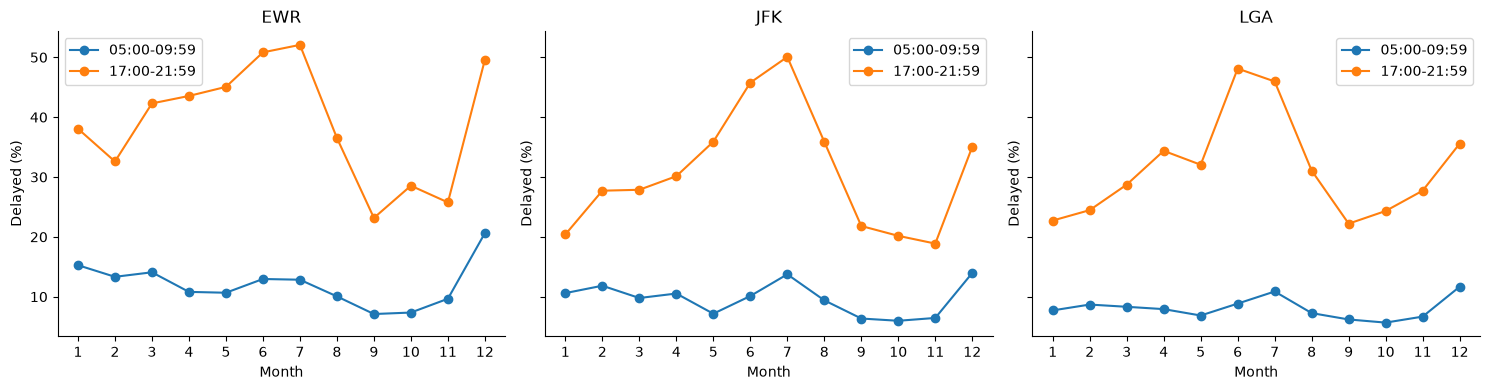

Evening delay rates exceed morning rates in 36/36 supported airport-month groups. The median within-group difference is 22.0 percentage points (range 9.8 to 39.3). This is an association within airport and month, not proof of cascading delays. Route and carrier mix may still differ.

period        evening  morning  evening_minus_morning_pp
origin month                                            
EWR    1        0.381    0.153                    22.801
       2        0.326    0.133                    19.271
       3        0.423    0.141                    28.222
       4        0.435    0.108                    32.740
       5        0.451    0.107                    34.400
       6        0.508    0.130                    37.872
       7        0.521    0.128                    39.241
       8        0.365    0.101                    26.470
       9        0.232    0.071                    16.062
       10       0.285    0.073                    21.195
       11       0.258    0.097                    16.104
       12       0.496    0.206                    28.973
JFK    1        0.204    0.106                     9.799
       2        0.277    0.118                    15.878
       3        0.279    0.098                    18.084
       4        0.301    0.105                    19.606
       5        0.359    0.072                    28.742
       6        0.458    0.101                    35.654
       7        0.501    0.137                    36.327
       8        0.359    0.094                    26.487
       9        0.218    0.064                    15.460
       10       0.202    0.060                    14.192
       11       0.189    0.064                    12.424
       12       0.350    0.140                    21.079
LGA    1        0.227    0.077                    15.014
       2        0.245    0.087                    15.777
       3        0.287    0.083                    20.413
       4        0.344    0.079                    26.451
       5        0.320    0.069                    25.192
       6        0.481    0.088                    39.269
       7        0.460    0.109                    35.093
       8        0.311    0.073                    23.809
       9        0.222    0.062                    16.008
       10       0.243    0.057                    18.656
       11       0.277    0.067                    21.043
       12       0.356    0.117                    23.905

2936

In [24]:
bands = df.loc[df.hour.between(5, 9) | df.hour.between(17, 21)].copy()
bands['period'] = np.where(bands.hour.between(5, 9), 'morning', 'evening')
period_summary = bands.groupby(['origin', 'month', 'period']).agg(flights=('flight_id', 'size'), observed_labels=('dep_delay', 'count'), delayed=('delayed_15', 'sum'))
period_summary['delay_rate'] = period_summary.delayed / period_summary.observed_labels.replace(0, np.nan)
period_summary['missing_rate'] = 1 - period_summary.observed_labels / period_summary.flights
period_rates = period_summary.delay_rate.unstack('period')
period_counts = period_summary.observed_labels.unstack('period')
supported = period_counts[['morning', 'evening']].ge(100).all(axis=1)
contrasts = period_rates.loc[supported].copy()
contrasts['evening_minus_morning_pp'] = (contrasts.evening - contrasts.morning) * 100
assert len(contrasts) > 0
period_summary.to_csv(TABLES / 'airport_month_time_bands.csv')
contrasts.to_csv(TABLES / 'evening_morning_contrasts.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, origin in zip(axes, sorted(airports.index)):
    group = contrasts.loc[origin]
    ax.plot(group.index, group.morning * 100, marker='o', label='05:00-09:59')
    ax.plot(group.index, group.evening * 100, marker='o', label='17:00-21:59')
    ax.set(title=origin, xlabel='Month', ylabel='Delayed (%)', xticks=range(1, 13))
    ax.legend()
save('followup_evening_within_groups')
higher = int(contrasts.evening.gt(contrasts.morning).sum())
evening_text = f'Evening delay rates exceed morning rates in {higher}/{len(contrasts)} supported airport-month groups. The median within-group difference is {contrasts.evening_minus_morning_pp.median():.1f} percentage points (range {contrasts.evening_minus_morning_pp.min():.1f} to {contrasts.evening_minus_morning_pp.max():.1f}). This is an association within airport and month, not proof of cascading delays. Route and carrier mix may still differ.'
display(Markdown(evening_text))
display(contrasts.round(3))
followup_report = chr(10).join(['# EDA follow-up findings', '', '## July concentration', july_text, '', '## Disrupted days', disruption_text, '', '## Comparable airline schedules', matched.to_string(index=False), matched_text, '', '## Morning versus evening', evening_text, '', 'All analyses are descriptive. No weather, causal attribution, clustering, or formal anomaly detection is included. See the notebook for thresholds, plots and coverage checks.']) + chr(10)
(ROOT / 'reports/eda_followups.md').write_text(followup_report, encoding='utf-8')